<a href="https://colab.research.google.com/github/mdeely24/stock_risk_analysis/blob/main/stock_risk_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
!pip install -q yfinance

In [22]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

tickers = ["AAPL", "MSFT", "JPM", "XOM", "JNJ"]
benchmark = "SPY"  # S&P 500 index fund

prices = yf.download(tickers + [benchmark], start="2019-01-01", auto_adjust=True)["Close"]
returns = prices.pct_change().dropna()

[*********************100%***********************]  6 of 6 completed


In [23]:
rf = 0.04  # annual risk-free rate
port_returns = returns[tickers].mean(axis=1)  # equal weight, rebalanced daily

all_returns = returns.copy()
all_returns["Portfolio"] = port_returns

summary = pd.DataFrame({
    "Annual Return": all_returns.mean() * 252,
    "Annual Volatility": all_returns.std() * np.sqrt(252),
})
summary["Sharpe Ratio"] = (summary["Annual Return"] - rf) / summary["Annual Volatility"]
summary

,Annual Return,Annual Volatility,Sharpe Ratio
Ticker,,,
AAPL,0.333275,0.305776,0.959117
JNJ,0.141255,0.194733,0.519969
JPM,0.226899,0.291691,0.640744
MSFT,0.262410,0.291574,0.762788
SPY,0.176505,0.191850,0.711517
XOM,0.212466,0.308057,0.559852
Portfolio,0.235261,0.195300,0.999801


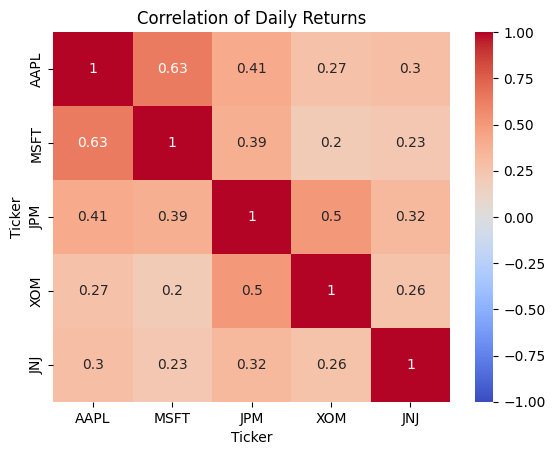

In [24]:
sns.heatmap(returns[tickers].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of Daily Returns")
plt.show()

Ticker
AAPL        -0.333605
JNJ         -0.273663
JPM         -0.436265
MSFT        -0.371485
SPY         -0.337173
XOM         -0.603474
Portfolio   -0.352306
dtype: float64
Average single stock: -0.4036982801012087


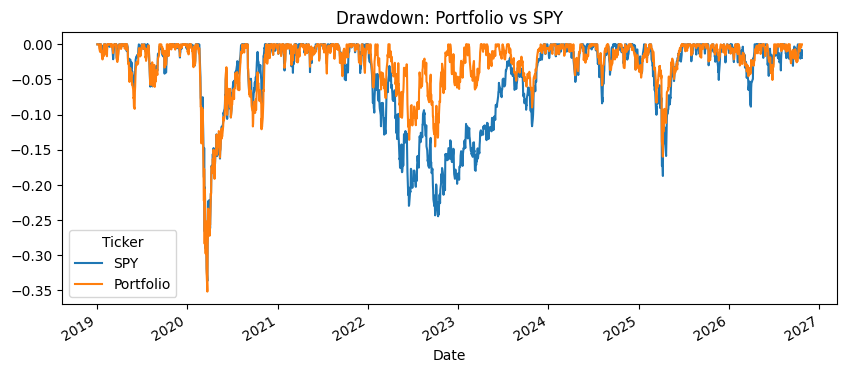

In [25]:
cum = (1 + all_returns).cumprod()
drawdown = cum / cum.cummax() - 1

print(drawdown.min())  # max drawdown per ticker, SPY, and Portfolio
print("Average single stock:", drawdown[tickers].min().mean())

drawdown[[benchmark, "Portfolio"]].plot(title="Drawdown: Portfolio vs SPY", figsize=(10, 4))
plt.show()

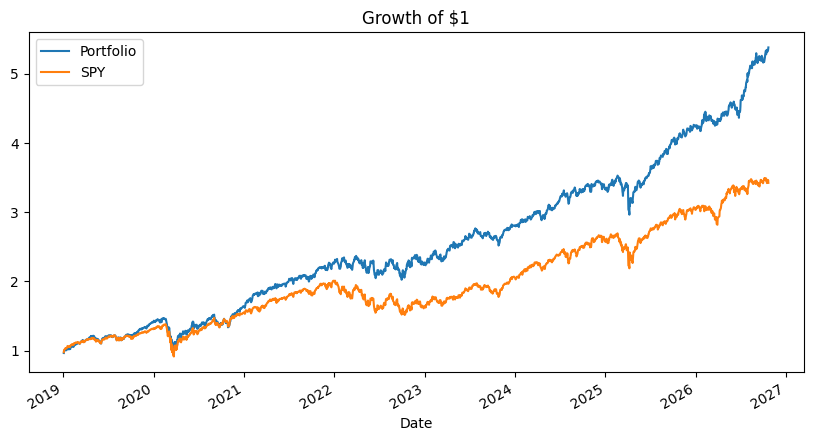

In [26]:
compare = pd.DataFrame({"Portfolio": port_returns, "SPY": returns[benchmark]})
(1 + compare).cumprod().plot(figsize=(10, 5), title="Growth of $1")
plt.show()

In [27]:
years = len(port_returns) / 252
cagr = (1 + port_returns).prod() ** (1 / years) - 1
spy_cagr = (1 + returns[benchmark]).prod() ** (1 / years) - 1
print(f"Portfolio CAGR: {cagr:.1%}  |  SPY CAGR: {spy_cagr:.1%}")

Portfolio CAGR: 24.1%  |  SPY CAGR: 17.1%


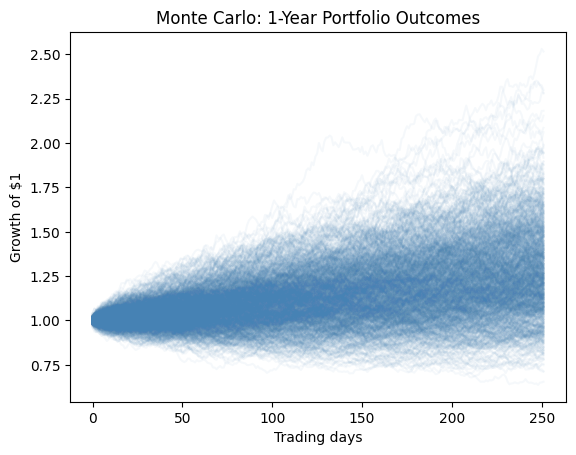

5th percentile: 0.9059584262856683
Median: 1.244355082884037
95th percentile: 1.7147181143709957


In [28]:
n_sims, n_days = 1000, 252
weights = np.array([1 / len(tickers)] * len(tickers))
mu = returns[tickers].mean().values
cov = returns[tickers].cov().values

np.random.seed(42)
sims = np.random.multivariate_normal(mu, cov, size=(n_sims, n_days))
paths = np.cumprod(1 + sims @ weights, axis=1)

plt.plot(paths.T, alpha=0.05, color="steelblue")
plt.title("Monte Carlo: 1-Year Portfolio Outcomes")
plt.xlabel("Trading days")
plt.ylabel("Growth of $1")
plt.show()

print("5th percentile:", np.percentile(paths[:, -1], 5))
print("Median:", np.median(paths[:, -1]))
print("95th percentile:", np.percentile(paths[:, -1], 95))